# Problem 3 — Final figures

Two plots and a Compact runtime table, using saved results only.
Panels: (a) Compact 1D, (b) Compact 2D, (c) Extended 1D, (d) Extended 2D.
Figures use Times New Roman 12 pt and export as PDF/PNG.


In [7]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if (ROOT / 'problem-3-global-pgm').is_dir():
    ROOT = ROOT / 'problem-3-global-pgm'
if not (ROOT / 'src/pgm.py').exists():
    raise RuntimeError('Open this notebook from the repository root or Problem 3 directory.')
loaded = sys.modules.get('src')
if loaded and Path(loaded.__file__).resolve().parent != ROOT / 'src':
    raise RuntimeError('Restart the kernel: another project has imported the src package.')
sys.path[:0] = [str(ROOT), str(ROOT / 'benchmark_pipeline')]
import importlib
import final_figures as _final_figures
_final_figures = importlib.reload(_final_figures)
load_saved_runs = _final_figures.load_saved_runs

# Saved full runs.
RUN_IDS = {'compact': 'c53a4a3e7d5709ad', 'extended': 'b8a9a308fb47e158'}
OUTPUT = ROOT / 'results/final_figures'

# Use the requested font.
font_manager.findfont(font_manager.FontProperties(family='Times New Roman'),
                      fallback_to_default=False)


FontPath('/System/Library/Fonts/Supplemental/Times New Roman.ttf', 0)

In [8]:
DATASETS, PROVENANCE = load_saved_runs(ROOT, RUN_IDS)
for study, info in PROVENANCE.items():
    print(f"{study.title()}: {info['case_budgets']:,} complete instance/budget groups")


Compact: 10,755 complete instance/budget groups
Extended: 17,234 complete instance/budget groups


In [9]:
# Reload plotting changes even when this cell is rerun on its own.
import importlib
import final_figures as _final_figures
_final_figures = importlib.reload(_final_figures)
FIGURES, RUNTIME_TABLE = _final_figures.create_outputs(DATASETS, OUTPUT)
PROVENANCE['report'] = {
    'weighting': 'equal instances; average unique budgets and states within instance',
    'runtime': 'Compact only; allocation + final PGM, or full Exhaustive search',
}
(OUTPUT / 'provenance.json').write_text(json.dumps(PROVENANCE, indent=2) + '\n')


2463

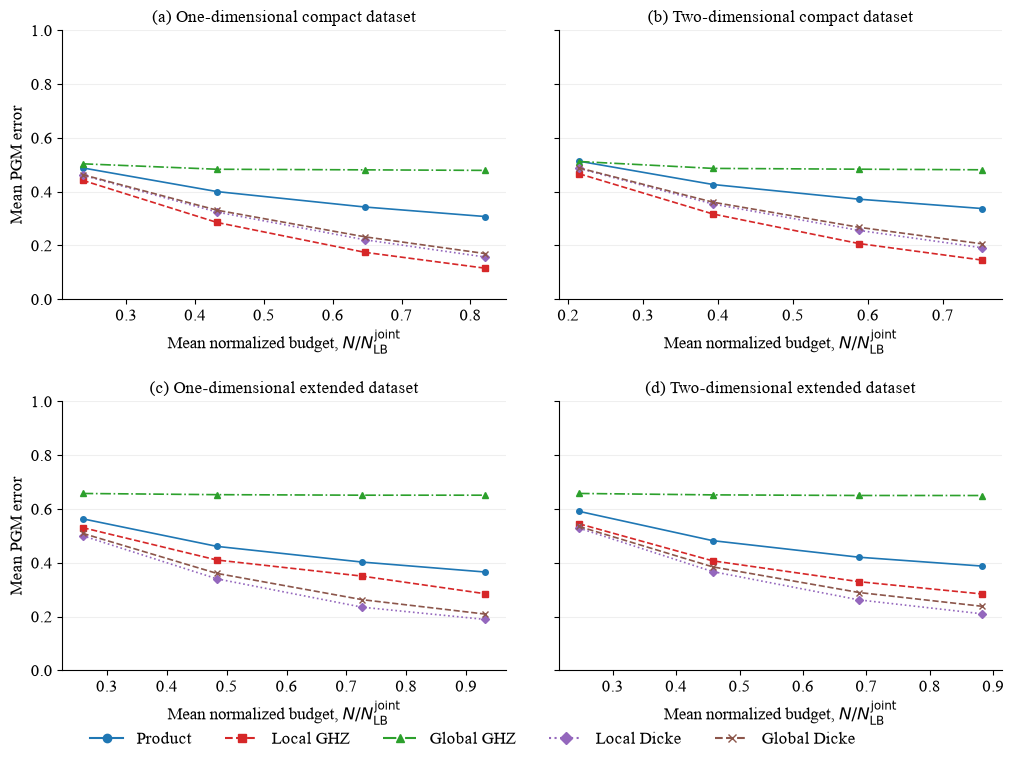

**Figure 1.** Mean PGM error for five input states, using Exhaustive allocations for Compact and VND for Extended.

In [10]:
display(FIGURES[0])
plt.close(FIGURES[0])
display(Markdown('**Figure 1.** Mean PGM error for five input states, using Exhaustive allocations for Compact and VND for Extended.'))


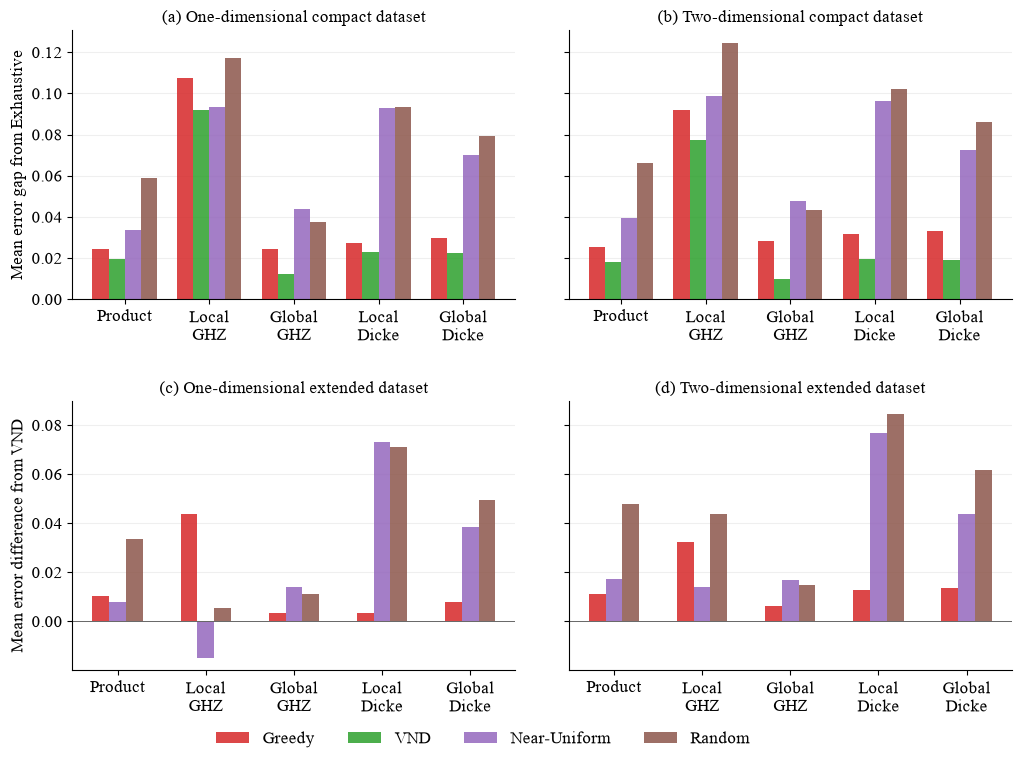

**Figure 2.** Allocation-method error differences from Exhaustive (Compact) and VND (Extended). VND is not an optimality benchmark.

In [11]:
display(FIGURES[1])
plt.close(FIGURES[1])
display(Markdown('**Figure 2.** Allocation-method error differences from Exhaustive (Compact) and VND (Extended). VND is not an optimality benchmark.'))


In [12]:
display(Markdown(RUNTIME_TABLE))
display(Markdown('**Table 1.** Mean runtime on Compact datasets for Exhaustive, Greedy, and VND, averaged over input states and budgets.'))


| Dimension | Method | Mean runtime (ms) |
|---|---|---:|
| 1D | Exhaustive | 68.607 |
| 1D | Greedy | 0.200 |
| 1D | VND | 0.363 |
| 2D | Exhaustive | 76.856 |
| 2D | Greedy | 0.203 |
| 2D | VND | 0.362 |

**Table 1.** Mean runtime on Compact datasets for Exhaustive, Greedy, and VND, averaged over input states and budgets.